# CVAE-GAN with normalised input frames

**The problem: the CVAE-GAN learns the average frame.** With the loss weights of the reference paper set equal,
$\tau_1 = \tau_2 = \tau_3 = \tfrac13$ (`cvae_gan.ipynb`), the trained encoder gives every latent slot
$\mu_{z,k} \approx 0$ and $\sigma_{z,k} \approx 1$, whatever frame it receives. The latent vector $z_k$ is then random
noise with no information about the frame, and the decoder can only redraw the average frame: its reconstruction
error is the same as always answering the mean frame.

**Why it happens.** Line 1 of the loss (the KL divergence) charges for every bit of information $z_k$ carries; line 2
rewards information only by the reconstruction error it removes. Lines 1 and 2 together are the loss of a standard
VAE that assumes Gaussian noise of variance $\sigma_x^2 = \tau_1/\tau_2$ on every tile. With equal weights that is noise
of about ±1, while the predicted crowd frames differ from their average by only about ±0.03 per tile. To the loss,
these differences look like noise, and carrying no information at all is the cheapest solution.


**The test performed here.** The reference paper applies the same loss to the movie ratings of individual users:
thousands of entries per user, and users that differ from each other a lot, so describing them is worth the KL charge.
Here the tiles differ by only about 0.03. Instead of changing the weights, this notebook changes the **scale of the
data**: the frames are normalised so that a tile deviates from its average by about 1, and the model keeps the equal
weights $\tau_1 = \tau_2 = \tau_3 = \tfrac13$. It is compared with the same model on the original frames, over several
splits of the viewers and several repeats (section 1). All RMSE values are on the original 0–1 tile scale.

## 0. Code

All the code used by this notebook is in the cells of this section; the experiment itself starts in section 1.

### Settings and paths

Every result is saved in `results/`; when the notebook is run again it loads the saved results instead of training
again, unless `RERUN = True`.

In [1]:
import os, time, random
from types import SimpleNamespace
from joblib import Parallel, delayed     # parallel runs that work on Linux, macOS and Windows

import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

# Paths are relative to this notebook's folder (run it with vae/ as the working directory):
#   ../dataset/360dataset/sensory/tile/          input:  one tile CSV per viewer
#   ../predictor/predictor_weights_trained.pt    input:  the settings of the trained FoV predictor
#   ./figures/, ./results/                       output: figures and results tables
DATA_ROOT      = os.path.join("..", "dataset", "360dataset")
PREDICTOR_FILE = os.path.join("..", "predictor", "predictor_weights_trained.pt")
FIG_DIR, RES_DIR = "figures", "results"
assert os.path.exists(PREDICTOR_FILE), f"{PREDICTOR_FILE} not found; run ../predictor/fov_predictor.ipynb first"
os.makedirs(FIG_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)

DEVICE = torch.device("cpu")
torch.set_num_threads(1)
N_WORKERS = max(1, min(6, (os.cpu_count() or 2) - 1))
RERUN = False                            # False: load saved results if they exist; True: train every run again

BLUE, ORANGE, GREEN, GREY = "#1f5fbf", "#d9480f", "#2b8a3e", "#7a7a7a"
pd.set_option("display.width", 200)

### Data and viewer folds

Each viewer's tile CSV becomes 12 FoV maps, one every 5 s (10 × 20 tiles, 1 = tile in view). The 50 viewers are split
into 5 folds of 10: viewer number $i$ goes to fold $i \bmod 5$. `split(f)` gives the roles of the folds in turn $f$
(section 1).

In [2]:
ck  = torch.load(PREDICTOR_FILE, map_location=DEVICE)
cfg = ck["cfg"]                                                # the predictor's settings (video, grid, order n, ...)
H, W, N = cfg["H"], cfg["W"], cfg["n"]
N_SAMPLES   = cfg["video_seconds"] // cfg["sample_every_s"]    # 12 FoV maps per viewer, one every 5 s
KS          = list(range(N + 1, N_SAMPLES + 1))                # the 7 predicted time steps k = 6..12
CROWD       = cfg["users_per_epoch"]                           # 10 viewers per crowd
PRED_EPOCHS = -(-int(cfg["video_hours"] * 3600) // (CROWD * (N_SAMPLES - N) * cfg["sample_every_s"]))   # 494
VAE_EPOCHS  = 2 * PRED_EPOCHS                                  # 988
U = ck["U"]                                                    # the 50 viewers


def parse_tile_csv(path):
    # ragged 'frame, tile, tile, ...' CSV  ->  (n_frames, H, W) array of 0/1
    occ = []
    with open(path) as f:
        f.readline()
        for line in f:
            parts = [p.strip() for p in line.strip().split(",")]
            if not parts or parts[0] == "":
                continue
            g = np.zeros((H, W), np.float32)
            for x in (int(p) for p in parts[1:] if p != ""):
                j, i = divmod(x, W)
                if 0 <= j < H and 0 <= i < W:
                    g[j, i] = 1.0
            occ.append(g)
    return np.stack(occ)


step = cfg["sample_every_s"] * cfg["fps"]
G = {}                                                         # G[u]: the 12 FoV maps of viewer u, (12, H, W)
for u in U:
    occ = parse_tile_csv(os.path.join(DATA_ROOT, "sensory", "tile", f"{cfg['video']}_{u}_tile.csv"))
    G[u] = occ[[min(k * step, len(occ)) - 1 for k in range(1, N_SAMPLES + 1)]]

# the 5 viewer folds: viewer number i goes to fold (i - 1) mod 5, so every fold holds 10 viewers spread over the list
FOLDS = [[u for i, u in enumerate(U) if i % 5 == f] for f in range(5)]


def split(f):
    # outer fold f: test = fold f; validation = fold f+1; inner training = the other 3 folds (30 viewers);
    # outer training = everything except the test fold (40 viewers)
    test, val = FOLDS[f], FOLDS[(f + 1) % 5]
    inner = [u for g in range(5) if g not in (f, (f + 1) % 5) for u in FOLDS[g]]
    outer = [u for g in range(5) if g != f for u in FOLDS[g]]
    return SimpleNamespace(test=test, val=val, inner_train=inner, outer_train=outer)

### The FoV predictor, trained per fold

`train_predictor(users)` trains the FoV predictor of `../predictor/fov_predictor.ipynb` with the same settings and
procedure, but only on the given viewers. `crowd_frames` averages the FoV maps of a group of viewers into crowd frames
and turns each window of 5 into a predicted frame $\hat F_k$, $k = 6, \dots, 12$: the input $X$ of the CVAE-GAN.
`training_frames` draws a new random group of 10 training viewers for each of the 988 epochs.

In [3]:
class CircularPad(nn.Module):
    # wrap columns (longitude, the 360-degree seam), zero-pad rows (latitude). x is (batch, C, H, W)
    def __init__(self, p):
        super().__init__(); self.p = p
    def forward(self, x):
        p = self.p
        x = torch.cat([x[..., -p:], x, x[..., :p]], dim=3)
        return nn.functional.pad(x, (0, 0, p, p))


class Order5Predictor(nn.Module):
    def __init__(self, base_rate, n=5, width=16):
        super().__init__()
        self.pad1, self.conv1 = CircularPad(1), nn.Conv2d(n, width, 3)
        self.pad2, self.conv2 = CircularPad(2), nn.Conv2d(width, width, 3, dilation=2)
        self.head = nn.Conv2d(width, 1, 1)
        for conv in (self.conv1, self.conv2, self.head):
            nn.init.xavier_uniform_(conv.weight); nn.init.zeros_(conv.bias)
        nn.init.constant_(self.head.bias, float(np.log(base_rate / (1 - base_rate))))

    def forward(self, x):                                       # x: (batch, H, W, n), oldest map first
        h = x.permute(0, 3, 1, 2)
        h = torch.relu(self.conv1(self.pad1(h)))
        h = torch.relu(self.conv2(self.pad2(h)))
        return torch.sigmoid(self.head(h)).squeeze(1)          # (batch, H, W)


def train_predictor(users):
    """The FoV predictor of ../predictor/fov_predictor.ipynb, trained on `users` only (same settings and procedure)."""
    torch.set_num_threads(1)
    X = np.stack([np.stack([np.moveaxis(G[u][k - 1 - N:k - 1], 0, -1) for k in KS]) for u in users]).astype(np.float32)
    Y = np.stack([np.stack([G[u][k - 1] for k in KS]) for u in users]).astype(np.float32)
    X_t, Y_t = torch.from_numpy(X), torch.from_numpy(Y)        # (users, 7, H, W, n) and (users, 7, H, W)
    random.seed(cfg["seed"]); np.random.seed(cfg["seed"]); torch.manual_seed(cfg["seed"])
    model = Order5Predictor(float(Y.mean()), N, cfg["width"])
    rng, used, groups = np.random.default_rng(cfg["seed"]), set(), []
    while len(groups) < PRED_EPOCHS:                           # one distinct group of 10 viewers per epoch
        s = tuple(sorted(rng.choice(len(users), CROWD, replace=False).tolist()))
        if s not in used:
            used.add(s); groups.append(s)
    for e, s in enumerate(groups, start=1):
        idx = torch.tensor(s)
        Xb, Yb = X_t[idx].reshape(-1, H, W, N), Y_t[idx].reshape(-1, H, W)
        loss = torch.mean(torch.sum(torch.square(model(Xb) - Yb), dim=(1, 2)))
        grads = torch.autograd.grad(loss, list(model.parameters()))
        with torch.no_grad():
            for v, g in zip(model.parameters(), grads):
                v.sub_(cfg["lr_a"] / (cfg["lr_b"] + e) * g)     # plain gradient descent, eta_e = a / (b + e)
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)
    return model


@torch.no_grad()
def crowd_frames(predictor, groups):
    """For each group of viewers: average their FoV maps into crowd frames F_k, then predict F_hat_6..F_hat_12."""
    X = []
    for users in groups:
        F = np.mean([G[u] for u in users], axis=0)                                     # (12, H, W)
        X.append(np.stack([np.moveaxis(F[k - 1 - N:k - 1], 0, -1) for k in KS]))       # (7, H, W, n)
    X = torch.from_numpy(np.concatenate(X).astype(np.float32))
    return predictor(X).numpy().reshape(len(groups), len(KS), H, W)


def training_frames(predictor, users, rng):
    """988 epochs: each one a random group of 10 of `users` -> its 7 predicted frames. Shape (988, 7, H, W)."""
    groups = [list(rng.choice(users, CROWD, replace=False)) for _ in range(VAE_EPOCHS)]
    return crowd_frames(predictor, groups)

### Normalisation

`make_normaliser(frames)` computes $\bar X$ and $s$ on the training frames of a run and returns the transform
$X' = (X - \bar X)/s$ and its inverse (explained in section 2).

In [4]:
def make_normaliser(frames):
    """X' = (X - X_bar) / s with X_bar the mean training frame and s the RMSE of always answering X_bar."""
    mean = frames.reshape(-1, H, W).mean(0)
    s = float(np.sqrt(np.mean((frames - mean) ** 2)))
    return SimpleNamespace(mean=mean, scale=s,
                           fwd=lambda A: ((A - mean) / s).astype(np.float32),
                           inv=lambda A: (A * s + mean).astype(np.float32))

### The CVAE-GAN

The same model, loss and training as `cvae_gan.ipynb`:

- **encoder** 200 → 128 → 64 → ($\mu_{z,k}$, $\log\sigma^2_{z,k}$), 10 latent slots; **decoder** 10 → 64 → 128 → 200;
  **discriminator** 200 → 128 → 64 → 1; LeakyReLU 0.2 in the hidden layers;
- $z_k = \mu_{z,k} + \sigma_{z,k}\,\varepsilon$, $\varepsilon \sim \mathcal N(0, 1)$;
- loss $\mathcal L = \tau_1\,\text{line 1 (KL)} + \tau_2\,\text{line 2 (reconstruction)} + \tau_3\,\text{line 3 (discriminator)}$;
- one epoch = one group's 7 frames = one discriminator step, then one encoder + decoder step; Adam, learning rate
  0.001, 988 epochs.

On normalised frames the decoder output is linear (no sigmoid) and its bias starts at 0; on original frames it ends in
a sigmoid whose bias starts at the average tile value. `evaluate` returns the reconstruction RMSE on the original
0–1 tile scale (decoding $\mu_{z,k}$), the number of **active** latent slots (mean $\sigma_{z,k} < 0.5$; a collapsed slot has
$\sigma_{z,k} \approx 1$) and the KL in nats.

In [5]:
def mlp(sizes, leak):
    return [m for a, b in zip(sizes, sizes[1:]) for m in (nn.Linear(a, b), nn.LeakyReLU(leak))]


class Encoder(nn.Module):
    # X  ->  (mu_{z,k}, log sigma_{z,k}^2)
    def __init__(self, L=10, hidden=(128, 64), leak=0.2):
        super().__init__()
        sizes = [H * W, *hidden]
        self.body, self.to_mu, self.to_lv = nn.Sequential(*mlp(sizes, leak)), nn.Linear(sizes[-1], L), nn.Linear(sizes[-1], L)

    def forward(self, X):
        h = self.body(X.flatten(1))
        return self.to_mu(h), self.to_lv(h)


class Decoder(nn.Module):
    # z_k -> X_recon. Sigmoid output for frames in [0, 1]; linear output for normalised frames.
    def __init__(self, L=10, hidden=(128, 64), leak=0.2, out_sigmoid=True, out_bias=0.0):
        super().__init__()
        sizes = [L, *hidden[::-1]]
        self.out_sigmoid = out_sigmoid
        self.net = nn.Sequential(*mlp(sizes, leak), nn.Linear(sizes[-1], H * W))
        nn.init.constant_(self.net[-1].bias, out_bias)

    def forward(self, z):
        y = self.net(z)
        return (torch.sigmoid(y) if self.out_sigmoid else y).view(-1, H, W)


class Discriminator(nn.Module):
    # D(X) in (0, 1): probability that a frame is a real predicted frame
    def __init__(self, d_hidden=(128, 64), leak=0.2):
        super().__init__()
        sizes = [H * W, *d_hidden]
        self.net = nn.Sequential(*mlp(sizes, leak), nn.Linear(sizes[-1], 1))

    def logit(self, X):
        return self.net(X.flatten(1)).squeeze(1)

    def forward(self, X):
        return torch.sigmoid(self.logit(X))


def draw_z(mu, lv):
    # z_k = mu + sigma * eps,  eps ~ N(0, 1)
    return mu + torch.exp(0.5 * lv) * torch.empty_like(mu).normal_()


def loss_enc(mu, lv):            # line 1: KL to N(0, 1), summed over the slots, mean over the batch
    return torch.mean(-0.5 * torch.sum(1 + lv - mu.pow(2) - lv.exp(), dim=1))

def loss_dec(X, X_recon):        # line 2: 1/2 ||X - X_recon||^2 summed over the tiles, mean over the batch
    return torch.mean(0.5 * torch.sum(torch.square(X - X_recon), dim=(1, 2)))

def loss_disc(disc, X, X_recon): # line 3: E[log D(X)] + E[log(1 - D(X_recon))]
    return (torch.mean(nn.functional.logsigmoid(disc.logit(X)))
            + torch.mean(nn.functional.logsigmoid(-disc.logit(X_recon))))


def train_cvaegan(train, tau, out_sigmoid, out_bias, lr=1e-3, decay=1e-6):
    """One epoch = one group's 7 frames = one discriminator step, then one encoder + decoder step."""
    enc, dec, disc = Encoder(), Decoder(out_sigmoid=out_sigmoid, out_bias=out_bias), Discriminator()
    opt_ed = torch.optim.Adam([*enc.parameters(), *dec.parameters()], lr=lr)
    opt_d  = torch.optim.Adam(disc.parameters(), lr=lr)
    scheds = [torch.optim.lr_scheduler.LambdaLR(o, lambda t: 1.0 / (1.0 + decay * t)) for o in (opt_ed, opt_d)]
    for X_np in train:
        X = torch.from_numpy(X_np)
        with torch.no_grad():                                   # (1) discriminator: maximise line 3
            mu, lv = enc(X)
            X_fake = dec(draw_z(mu, lv))
        L_D = -tau[2] * loss_disc(disc, X, X_fake)
        opt_d.zero_grad(); L_D.backward(); opt_d.step()
        mu, lv = enc(X)                                         # (2) encoder + decoder: minimise L
        X_recon = dec(draw_z(mu, lv))
        L = tau[0] * loss_enc(mu, lv) + tau[1] * loss_dec(X, X_recon) + tau[2] * loss_disc(disc, X, X_recon)
        opt_ed.zero_grad(); L.backward(); opt_ed.step()
        for sch in scheds:
            sch.step()
    enc.eval(); dec.eval(); disc.eval()
    return enc, dec


@torch.no_grad()
def evaluate(enc, dec, A, scale=1.0):
    """Reconstruction RMSE on the original tile scale (decoding mu), active slots and KL on the frames A."""
    A_t = torch.from_numpy(A)
    mu, lv = enc(A_t)
    sig = torch.exp(0.5 * lv).mean(0)
    return {"rmse": float(torch.sqrt(torch.mean(torch.square(dec(mu) - A_t)))) * scale,
            "active": int((sig < 0.5).sum()), "kl": float(loss_enc(mu, lv))}


def rmse(p, y):
    return float(np.sqrt(np.mean((np.asarray(p) - np.asarray(y)) ** 2)))

### Running many trainings

`run_one(task)` trains one CVAE-GAN for one turn, stage (`"val"` or `"test"`), setting and repeat, and scores it on the
7 frames of the validation or test fold. It also records the error of always answering the mean training frame on
the same frames. `run_all(tasks, csv)` runs a list of tasks in parallel and saves one row per run.

In [6]:
# The fold predictors: for outer fold f, one predictor trained on the 30 inner-training viewers (used to choose the
# setting on the validation fold) and one trained on the 40 outer-training viewers (used for the test fold).
def fold_predictors():
    t0, P = time.time(), {}
    for f in range(5):
        sp = split(f)
        P[(f, "val")]  = train_predictor(sp.inner_train)
        P[(f, "test")] = train_predictor(sp.outer_train)
    print("10 fold predictors trained")
    return P


def run_one(task):
    """Train one CVAE-GAN and score it. task = (fold, stage, tau, normalised, repeat); stage is 'val' or 'test'.

    No random seed is fixed: every run starts from fresh random numbers. The seed it happened to use is recorded so
    that any single run can be repeated exactly.
    """
    f, stage, tau, normalised, rep = task
    torch.set_num_threads(1)
    seed = int.from_bytes(os.urandom(4), "little")
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    sp, pred = split(f), PREDICTORS[(f, stage)]
    train = training_frames(pred, sp.inner_train if stage == "val" else sp.outer_train, np.random.default_rng(seed))
    A = crowd_frames(pred, [sp.val if stage == "val" else sp.test])[0]          # the 7 frames that are scored
    mean_frame = train.reshape(-1, H, W).mean(0)
    if normalised:
        nm = make_normaliser(train)
        enc, dec = train_cvaegan(nm.fwd(train), tau, out_sigmoid=False, out_bias=0.0)
        ev = evaluate(enc, dec, nm.fwd(A), nm.scale)
    else:
        m = float(train.mean())
        enc, dec = train_cvaegan(train, tau, out_sigmoid=True, out_bias=float(np.log(m / (1 - m))))
        ev = evaluate(enc, dec, A)
    return {"fold": f + 1, "stage": stage, "tau_1": tau[0], "tau_2": tau[1], "tau_3": tau[2],
            "normalised": normalised, "repeat": rep + 1, "seed": seed, **ev,
            "mean_frame_rmse": rmse(np.broadcast_to(mean_frame, A.shape), A)}


def run_all(tasks, csv_name):
    """Run every task in parallel (or load the saved results), and save them to results/csv_name."""
    path = os.path.join(RES_DIR, csv_name)
    if os.path.exists(path) and not RERUN:
        print(f"loaded {len(pd.read_csv(path))} saved runs from {path}  (set RERUN = True to train them again)")
        return pd.read_csv(path)
    t0 = time.time()
    rows = Parallel(n_jobs=N_WORKERS)(delayed(run_one)(t) for t in tasks)
    df = pd.DataFrame(rows)
    df.to_csv(path, index=False)
    print(f"{len(df)} runs saved to {path}")
    return df

### Summaries and figures

Helpers that average the runs of each setting, pick the setting with the lowest validation RMSE in each turn, and draw
the figures.

In [7]:
def fmt(t):
    return "1/3" if abs(t - 1 / 3) < 1e-9 else (f"{t:.0e}".replace("e-0", "e-") if t < 0.01 else f"{t:.4g}")


def summarise(df, by=("tau_1", "tau_2", "tau_3")):
    # one row per setting: mean and standard deviation of the RMSE over all its runs, mean active slots and KL
    g = df.groupby(list(by))
    out = g.agg(rmse_mean=("rmse", "mean"), rmse_std=("rmse", "std"), active=("active", "mean"),
                kl=("kl", "mean"), mean_frame=("mean_frame_rmse", "mean"), runs=("rmse", "size")).reset_index()
    if "tau_1" in by:
        out["ratio"] = out.tau_1 / out.tau_2
    return out


def choose_per_fold(val, by=("tau_1", "tau_2", "tau_3")):
    # in each turn: the setting with the lowest validation RMSE averaged over its repeats
    m = val.groupby(["fold", *by]).rmse.mean().reset_index()
    return m.loc[m.groupby("fold").rmse.idxmin()].reset_index(drop=True)


def pm(mean, std, d=4):
    return f"{mean:.{d}f} ± {std:.{d}f}"


def eigenvalues(frames):
    # variance of the frames along each principal direction, largest first (sums to the total variance)
    A = frames.reshape(-1, H * W).astype(np.float64)
    s = np.linalg.svd(A - A.mean(0), compute_uv=False)
    return s ** 2 / len(A)


def plot_eigenvalues(lam, ratios, title, path):
    fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
    ax.semilogy(np.arange(1, 31), lam[:30], "o-", color=BLUE, ms=4, label="variance of the frames along direction $i$")
    for r, ls in zip(ratios, ["-", "--", "-.", ":"]):
        ax.axhline(r, color=ORANGE, ls=ls, lw=1.2, label=f"$\\tau_1/\\tau_2$ = {r:g}: {int((lam > r).sum())} directions above")
    ax.axvline(10.5, color=GREY, lw=0.8)
    ax.text(10.7, lam[:30].min(), "10 latent slots", color=GREY, fontsize=8, va="bottom")
    ax.set_xlabel("principal direction $i$"); ax.set_ylabel("variance (log scale)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, frameon=False, loc="upper right"); ax.spines[["top", "right"]].set_visible(False)
    fig.savefig(path, dpi=150)
    plt.show()


def plot_validation(summary, title, path):
    # mean +- standard deviation of the validation RMSE against tau_1/tau_2, one line per tau_3; right: active slots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2), constrained_layout=True)
    for t3, color, ls, mk in zip(sorted(summary.tau_3.unique(), reverse=True), [BLUE, ORANGE, GREEN], ["-", "--", "-."], ["o", "s", "^"]):
        s = summary[np.isclose(summary.tau_3, t3)].sort_values("ratio")
        ax1.errorbar(s.ratio, s.rmse_mean, yerr=s.rmse_std, ls=ls, marker=mk, color=color, capsize=3, label=f"$\\tau_3$ = {fmt(t3)}")
        ax2.plot(s.ratio, s.active, ls=ls, marker=mk, color=color, label=f"$\\tau_3$ = {fmt(t3)}")
    ax1.axhline(summary.mean_frame.mean(), color=GREY, ls=":", lw=1.2, label="mean frame (no latent)")
    ax1.set_ylabel("validation RMSE (mean ± std of 25 runs)"); ax1.set_title("Reconstruction error", fontsize=10)
    ax2.set_ylim(-0.5, 10.5); ax2.set_ylabel("active slots (of 10, mean of 25 runs)"); ax2.set_title("Latent slots in use", fontsize=10)
    for a in (ax1, ax2):
        a.set_xscale("log"); a.set_xlabel("$\\tau_1 / \\tau_2$ (log scale)")
        a.legend(fontsize=8, frameon=False); a.grid(alpha=0.25); a.spines[["top", "right"]].set_visible(False)
    fig.suptitle(title, fontsize=11)
    fig.savefig(path, dpi=150)
    plt.show()


@torch.no_grad()
def example_run(f, tau, normalised):
    # one extra run of a setting in turn f (trained on the 40 non-test viewers), for the figures: the 7 test frames,
    # their reconstruction from one drawn z_k, and the mean sigma of each latent slot
    sp, pred = split(f), PREDICTORS[(f, "test")]
    train = training_frames(pred, sp.outer_train, np.random.default_rng())
    A = crowd_frames(pred, [sp.test])[0]
    with torch.enable_grad():
        if normalised:
            nm = make_normaliser(train)
            enc, dec = train_cvaegan(nm.fwd(train), tau, out_sigmoid=False, out_bias=0.0)
        else:
            m = float(train.mean())
            enc, dec = train_cvaegan(train, tau, out_sigmoid=True, out_bias=float(np.log(m / (1 - m))))
    X = torch.from_numpy(nm.fwd(A) if normalised else A)
    mu, lv = enc(X)
    R = dec(draw_z(mu, lv)).numpy()
    return A, (nm.inv(R) if normalised else R), torch.exp(0.5 * lv).mean(0).numpy()


def plot_reconstruction(A, R, title, path):
    vm, err = float(max(A.max(), R.max())), np.abs(R - A)
    fig, axes = plt.subplots(3, len(KS), figsize=(2.4 * len(KS), 5.0), constrained_layout=True)
    for col, k in enumerate(KS):
        im0 = axes[0, col].imshow(A[col], cmap="Blues", vmin=0, vmax=vm, interpolation="nearest")
        axes[0, col].set_title(f"input $\\hat F_{{{k}}}$", fontsize=9)
        axes[1, col].imshow(R[col], cmap="Blues", vmin=0, vmax=vm, interpolation="nearest")
        axes[1, col].set_title(f"redrawn, RMSE {rmse(R[col], A[col]):.4f}", fontsize=8)
        im2 = axes[2, col].imshow(err[col], cmap="Oranges", vmin=0, vmax=float(err.max()), interpolation="nearest")
        axes[2, col].set_title("|redrawn - input|", fontsize=8)
    for ax in axes.ravel():
        ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im0, ax=axes[:2], shrink=0.8, label="share of the crowd")
    fig.colorbar(im2, ax=axes[2], shrink=0.9, label="error")
    fig.suptitle(title, fontsize=11)
    fig.savefig(path, dpi=150)
    plt.show()


def plot_slots(sigma, title, path):
    dims = np.arange(1, len(sigma) + 1)
    fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
    ax.bar(dims, sigma, color=[BLUE if s < 0.5 else "#bbbbbb" for s in sigma])
    ax.axhline(1.0, color=GREY, ls=":", lw=1.2, label="standard normal, sigma = 1 (collapsed)")
    ax.axhline(0.5, color=GREY, ls="--", lw=1, label="active threshold 0.5")
    ax.set_xticks(dims); ax.set_xlabel("latent slot"); ax.set_ylabel("mean sigma_z (test fold)")
    ax.set_title(title, fontsize=10); ax.legend(fontsize=8, frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.savefig(path, dpi=150)
    plt.show()

## 1. How the two models are compared

The two models are fixed in advance (original frames and normalised frames, both with equal weights), so nothing is
chosen here and both can be scored directly on test data.

- **Viewer folds.** The 50 viewers are split into 5 folds of 10 (viewer number $i$ goes to fold $i \bmod 5$). Each fold
  takes one turn as the **test fold**; the other 40 viewers are the training viewers of that turn. Every viewer is
  tested exactly once.
- **A predictor for every turn.** The FoV predictor is retrained in every turn on the 40 training viewers only, with
  the settings of `../predictor/fov_predictor.ipynb`, so the test frames come from a predictor that has never seen the
  test viewers.
- **Repeats.** Both models are trained 5 times in every turn, each time from fresh random starting weights and fresh
  random groups of viewers. No random seed is fixed; the seed of every run is saved with its result.

That is 2 models × 5 turns × 5 repeats = 50 runs. A fold has 10 viewers, which form one crowd and therefore 7 predicted
frames. (The cell below also trains the validation predictors used by `cvae_gan_normalised_and_diff_weights.ipynb`;
they are not used here.)

In [8]:
fold_table = pd.DataFrame([{"turn": f + 1, "test fold": f + 1, "validation fold": (f + 1) % 5 + 1,
                            "test viewers": ", ".join(u.replace("user", "") for u in split(f).test)} for f in range(5)])
print(fold_table.to_string(index=False))

# the 10 fold predictors (two per turn), trained in parallel
jobs = [(f, stage) for f in range(5) for stage in ("val", "test")]
t0 = time.time()
trained = Parallel(n_jobs=N_WORKERS)(delayed(train_predictor)(split(f).inner_train if s == "val" else split(f).outer_train)
                                     for f, s in jobs)
PREDICTORS = dict(zip(jobs, trained))
print(f"\n10 fold predictors trained "
      f"(turn f: one on its 30 training viewers for validation, one on its 40 non-test viewers for the test)")

 turn  test fold  validation fold                           test viewers
    1          1                2 01, 06, 11, 16, 21, 26, 31, 36, 41, 46
    2          2                3 02, 07, 12, 17, 22, 27, 32, 37, 42, 47
    3          3                4 03, 08, 13, 18, 23, 28, 33, 38, 43, 48
    4          4                5 04, 09, 14, 19, 24, 29, 34, 39, 44, 49
    5          5                1 05, 10, 15, 20, 25, 30, 35, 40, 45, 50



10 fold predictors trained (turn f: one on its 30 training viewers for validation, one on its 40 non-test viewers for the test)


## 2. How the frames are normalised

$$X' = \frac{X - \bar X}{s}, \qquad \bar X = \text{the mean training frame}, \qquad
s = \sqrt{\tfrac{1}{N\,D}\textstyle\sum_n \lVert X_n - \bar X\rVert^2} = \text{the RMSE of always answering } \bar X.$$

After this, a tile deviates from its average by about 1 instead of about 0.03. $\bar X$ and $s$ are computed in every
run from that run's training frames only and then applied to the frames it is scored on.

- **One scalar $s$ for all tiles, not one per tile.** Tiles far from the action hardly ever change; dividing each of
  them by its own tiny spread would blow tiny fluctuations up to the same size as the real movement of the crowd.
  One $s$ keeps the shape of the frames and only changes their scale.
- **The decoder's output is linear**, without the sigmoid: normalised tiles are no longer between 0 and 1 and can be
  negative. Its output bias starts at 0, the mean of $X'$.
- **The discriminator** sees normalised real and redrawn frames.
- **The RMSE is converted back** to the original tile scale, $\mathrm{RMSE} = s \cdot \mathrm{RMSE}'$ (the offset
  $\bar X$ cancels), so the numbers compare directly with models trained on the original frames.

**Why this has the same effect as changing $\tau$.** Dividing the frames by $s$ divides the variance along every
principal direction by $s^2$, so the rule "a slot is used if $\lambda_i/s^2 > \tau_1/\tau_2$" is the rule
"$\lambda_i > s^2 \cdot \tau_1/\tau_2$" on the original frames. With equal weights, normalising acts like
$\tau_1/\tau_2 = s^2 \approx 0.0009$.

The figures show one test frame of turn 1 before and after normalising.

s = 0.0278


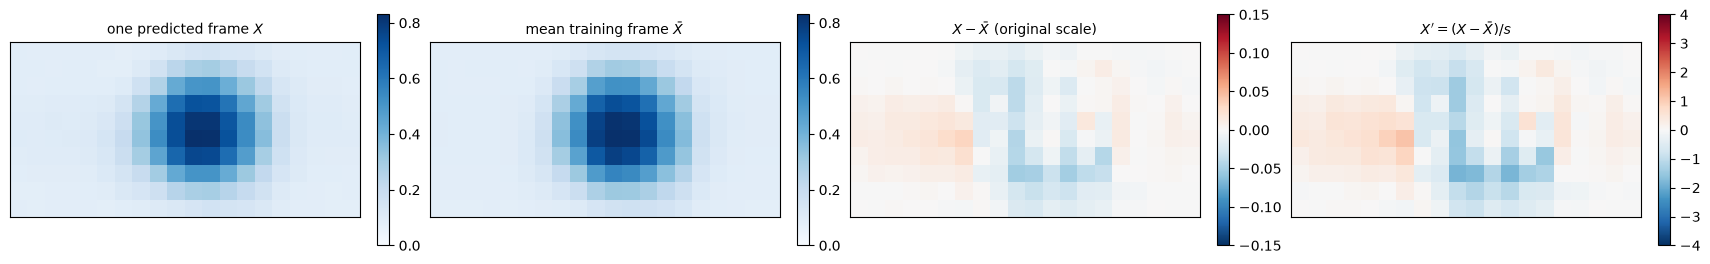

In [9]:
sp, pred = split(0), PREDICTORS[(0, "test")]
NORM = make_normaliser(training_frames(pred, sp.outer_train, np.random.default_rng()))   # one set of training frames
X0 = crowd_frames(pred, [sp.test])[0][-1]                                                 # the last test frame of turn 1
print(f"s = {NORM.scale:.4f}")
panels = [(X0, "one predicted frame $X$", "Blues", 0, float(X0.max())),
          (NORM.mean, "mean training frame $\\bar X$", "Blues", 0, float(X0.max())),
          (X0 - NORM.mean, "$X - \\bar X$ (original scale)", "RdBu_r", -0.15, 0.15),
          (NORM.fwd(X0), "$X' = (X - \\bar X)/s$", "RdBu_r", -4, 4)]
fig, axes = plt.subplots(1, 4, figsize=(17, 2.8), constrained_layout=True)
for ax, (m, t, cm, lo, hi) in zip(axes, panels):
    im = ax.imshow(m, cmap=cm, vmin=lo, vmax=hi, interpolation="nearest")
    ax.set_title(t, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=ax, shrink=0.85)
fig.savefig(os.path.join(FIG_DIR, "normalised_tiles_example.png"), dpi=150)
plt.show()

### Every tile, before and after normalising

The same frame with the value of each of the 20 × 10 tiles written in it. **Top:** the original values, the share of
the crowd looking at each tile (0 to 1). **Bottom:** the normalised values $X' = (X - \bar X)/s$. A tile with $X' = 0$
is exactly at its average; $X' = +2$ means two "typical differences" above it.

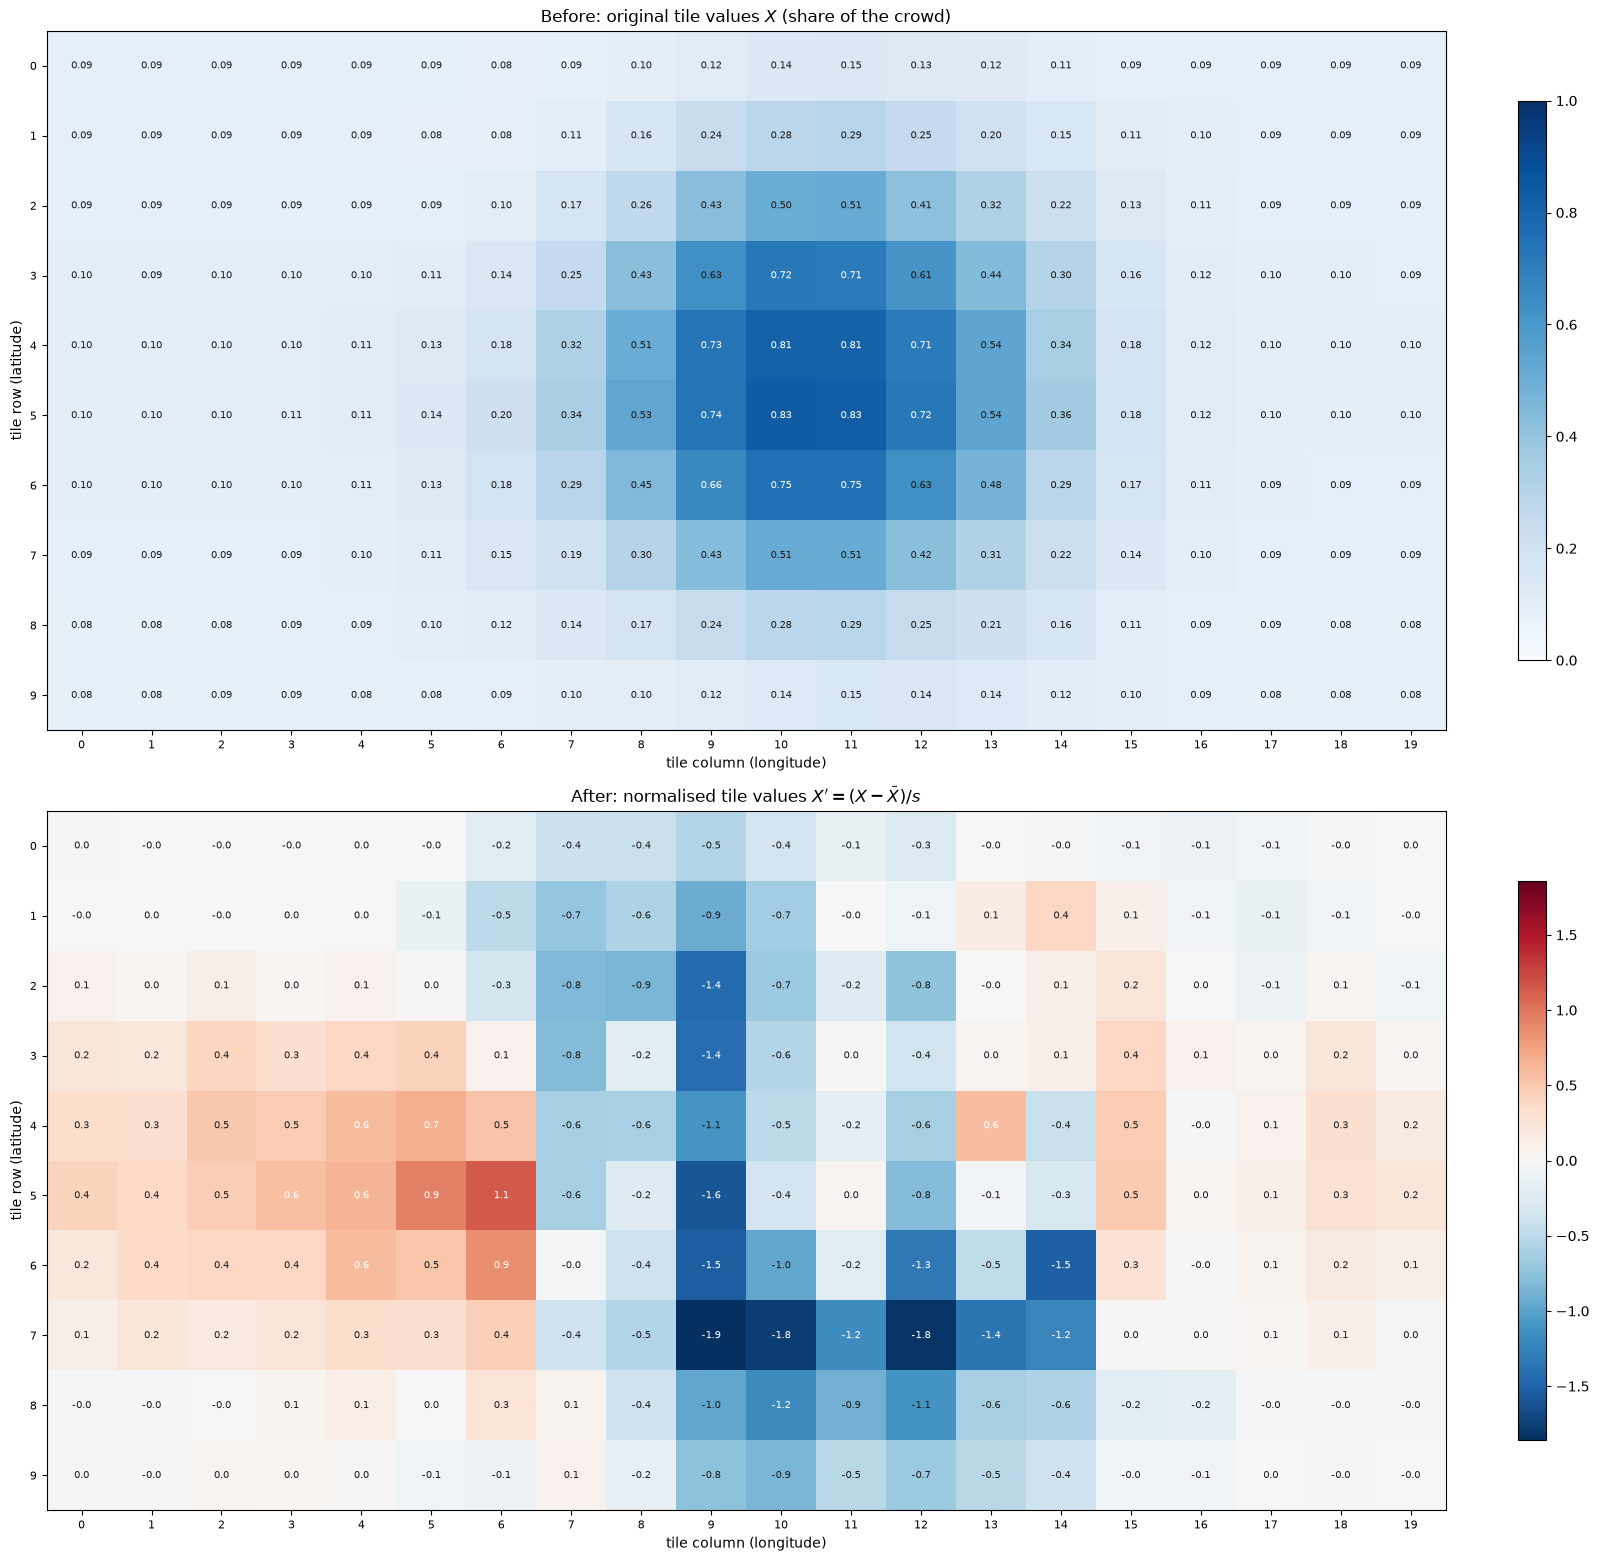

In [10]:
Xn = NORM.fwd(X0)
lim = float(np.abs(Xn).max())
fig, axes = plt.subplots(2, 1, figsize=(16, 15.5), constrained_layout=True)
for ax, m, title, cm, lo, hi, f in [
        (axes[0], X0, "Before: original tile values $X$ (share of the crowd)", "Blues", 0, 1, "{:.2f}"),
        (axes[1], Xn, "After: normalised tile values $X' = (X - \\bar X)/s$", "RdBu_r", -lim, lim, "{:.1f}")]:
    im = ax.imshow(m, cmap=cm, vmin=lo, vmax=hi, interpolation="nearest")
    for (r, c), v in np.ndenumerate(m):
        strong = (v - lo) / (hi - lo) > 0.65 or (cm == "RdBu_r" and (v - lo) / (hi - lo) < 0.2)
        ax.text(c, r, f.format(v), ha="center", va="center", fontsize=7.5, color="white" if strong else "#1d1d1f")
    ax.set_xticks(range(W)); ax.set_yticks(range(H)); ax.tick_params(labelsize=8)
    ax.set_xlabel("tile column (longitude)"); ax.set_ylabel("tile row (latitude)")
    ax.set_title(title, fontsize=12)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(os.path.join(FIG_DIR, "normalised_tiles_values.png"), dpi=130)
plt.show()

## 3. What normalising does to the variance per direction

The variance of the normalised training frames along each principal direction, against the ratio $\tau_1/\tau_2 = 1$ of
equal weights. A latent slot is worth using along a direction whose variance is above that line (exact for a linear
encoder and decoder, a guide for these networks). Before normalising, every direction is far below it.

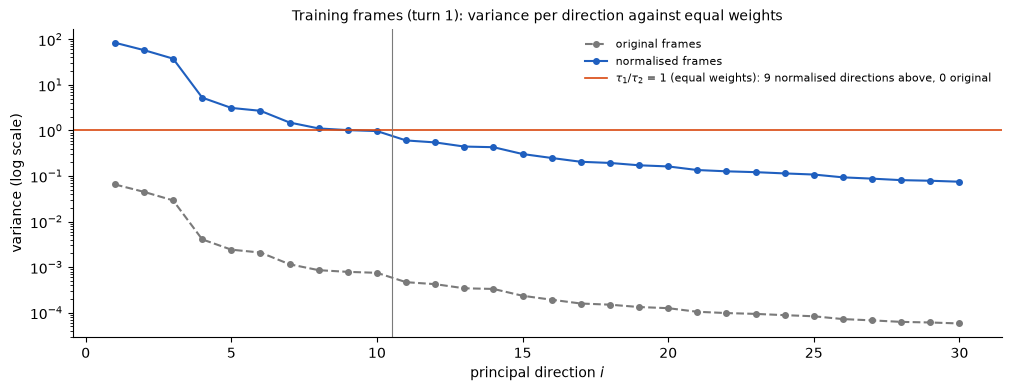

In [11]:
lam_orig = eigenvalues(training_frames(PREDICTORS[(0, "test")], split(0).outer_train, np.random.default_rng()))
lam = lam_orig / NORM.scale ** 2
fig, ax = plt.subplots(figsize=(10, 3.8), constrained_layout=True)
ax.semilogy(np.arange(1, 31), lam_orig[:30], "o--", color=GREY, ms=4, label="original frames")
ax.semilogy(np.arange(1, 31), lam[:30], "o-", color=BLUE, ms=4, label="normalised frames")
ax.axhline(1.0, color=ORANGE, lw=1.2, label=f"$\\tau_1/\\tau_2$ = 1 (equal weights): {int((lam > 1).sum())} normalised directions above, "
                                            f"{int((lam_orig > 1).sum())} original")
ax.axvline(10.5, color=GREY, lw=0.8)
ax.set_xlabel("principal direction $i$"); ax.set_ylabel("variance (log scale)")
ax.set_title("Training frames (turn 1): variance per direction against equal weights", fontsize=10)
ax.legend(fontsize=8, frameon=False); ax.spines[["top", "right"]].set_visible(False)
fig.savefig(os.path.join(FIG_DIR, "normalised_tiles_eigenvalues.png"), dpi=150)
plt.show()

## 4. Test results

Both models, 5 repeats in each of the 5 turns, scored on the test fold of the turn. The table gives the test RMSE per
turn (mean ± standard deviation of the 5 repeats) and over all 25 runs, the number of active latent slots, and the
error of always answering the mean frame on the same frames.

In [12]:
TAU_EQ = (1 / 3, 1 / 3, 1 / 3)
tasks = [(f, "test", TAU_EQ, normalised, rep) for f in range(5) for normalised in (False, True) for rep in range(5)]
TEST = run_all(tasks, "normalised_tiles_test.csv")

orig, norm = TEST[~TEST.normalised], TEST[TEST.normalised]
rows = []
for f in range(1, 6):
    o, n = orig[orig.fold == f], norm[norm.fold == f]
    rows.append({"turn": f, "original frames": pm(o.rmse.mean(), o.rmse.std()), "active (orig.)": o.active.mean(),
                 "normalised frames": pm(n.rmse.mean(), n.rmse.std()), "active (norm.)": n.active.mean(),
                 "mean frame": n.mean_frame_rmse.mean()})
rows.append({"turn": "all", "original frames": pm(orig.rmse.mean(), orig.rmse.std()), "active (orig.)": orig.active.mean(),
             "normalised frames": pm(norm.rmse.mean(), norm.rmse.std()), "active (norm.)": norm.active.mean(),
             "mean frame": TEST.mean_frame_rmse.mean()})
pd.DataFrame(rows).round({"active (orig.)": 1, "active (norm.)": 1, "mean frame": 4})

loaded 50 saved runs from results/normalised_tiles_test.csv  (set RERUN = True to train them again)


,turn,original frames,active (orig.),normalised frames,active (norm.),mean frame
0,1,0.0217 ± 0.0010,0.0,0.0097 ± 0.0011,4.2,0.0250
1,2,0.0262 ± 0.0016,0.0,0.0090 ± 0.0005,4.0,0.0267
2,3,0.0322 ± 0.0033,0.0,0.0101 ± 0.0002,4.4,0.0263
3,4,0.0326 ± 0.0030,0.0,0.0122 ± 0.0006,4.0,0.0327
4,5,0.0464 ± 0.0021,0.0,0.0096 ± 0.0006,4.2,0.0394
5,all,0.0318 ± 0.0088,0.0,0.0101 ± 0.0013,4.2,0.0300


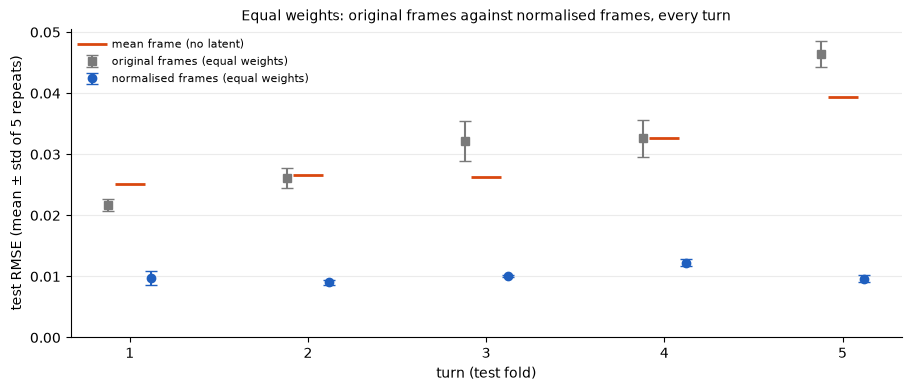

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.8), constrained_layout=True)
x = np.arange(1, 6)
for d, label, color, mk, off in [(orig, "original frames", GREY, "s", -0.12), (norm, "normalised frames", BLUE, "o", 0.12)]:
    g = d.groupby("fold").rmse
    ax.errorbar(x + off, g.mean(), yerr=g.std(), fmt=mk, color=color, capsize=4, label=f"{label} (equal weights)")
ax.plot(x, TEST.groupby("fold").mean_frame_rmse.mean(), "_", color=ORANGE, ms=22, mew=2, label="mean frame (no latent)")
ax.set_xticks(x); ax.set_xlabel("turn (test fold)"); ax.set_ylabel("test RMSE (mean ± std of 5 repeats)")
ax.set_ylim(0, None); ax.set_title("Equal weights: original frames against normalised frames, every turn", fontsize=10)
ax.legend(fontsize=8, frameon=False); ax.grid(alpha=0.25, axis="y"); ax.spines[["top", "right"]].set_visible(False)
fig.savefig(os.path.join(FIG_DIR, "normalised_tiles_test.png"), dpi=150)
plt.show()

## 5. One example run

One more training of the normalised model with equal weights in turn 1: the 7 test frames, their reconstruction from
one drawn $z_k$ (converted back to the original scale), and the spread $\sigma_{z,k}$ of each latent slot.

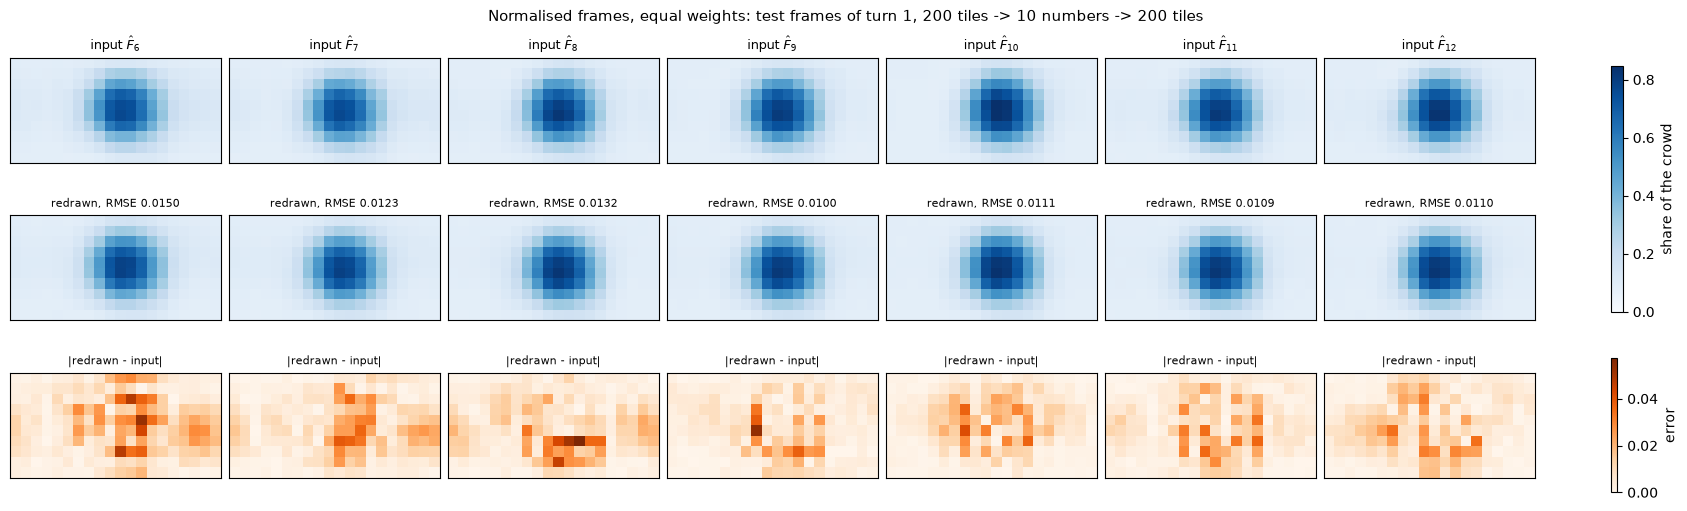

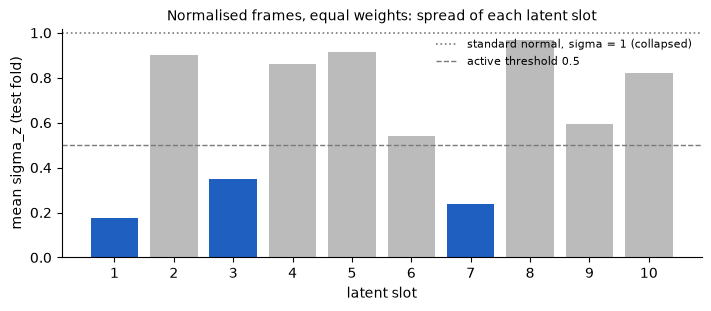

In [14]:
A, R, sigma = example_run(0, TAU_EQ, True)
plot_reconstruction(A, R, "Normalised frames, equal weights: test frames of turn 1, 200 tiles -> 10 numbers -> 200 tiles",
                    os.path.join(FIG_DIR, "normalised_tiles_example_reconstruction.png"))
plot_slots(sigma, "Normalised frames, equal weights: spread of each latent slot",
           os.path.join(FIG_DIR, "normalised_tiles_example_slots.png"))

## 6. What the results show

| test folds, 5 turns × 5 repeats | test RMSE | active slots (of 10) |
|---|---|---|
| mean frame (no latent) | 0.0300 | – |
| original frames, equal weights | 0.0318 ± 0.0088 | 0.0 |
| **normalised frames, equal weights** | **0.0101 ± 0.0013** | **4.2** |

- **Normalising removes the collapse in every turn.** With the same equal weights, the test RMSE is 0.009 – 0.012 in
  every turn on normalised frames, against 0.022 – 0.046 on original frames: about three times below the mean frame.
- **On original frames the model collapses in all 25 runs** (no slot in use) and is no better than the mean frame.
- **Not every slot is used.** With equal weights only the directions whose normalised variance is above 1 are worth a
  slot (section 3), and on average 4.2 of the 10 slots carry information.

### Conclusion

Normalising the frames, with the reference paper's equal weights $\tau_1 = \tau_2 = \tau_3 = \tfrac13$, lowers the test RMSE
from **0.0318 ± 0.0088** to **0.0101 ± 0.0013** and is better in all 5 turns. With equal weights about 4 of the 10 latent
slots are used; `cvae_gan_normalised_and_diff_weights.ipynb` tests whether changing the weights as well helps further.